# Reading the 'Why' That Numbers Don't Tell You — a qualitative data analysis practice

In this practice we implement the text-based qualitative analysis methods from the chapter on a
synthetic review dataset. For e-commerce product reviews, we compare **what words** 5-star (very
satisfied) and 1-star (very dissatisfied) reviews are written in, using several methods in turn. We
count words (frequency), find the words that separate the two groups (weighting), draw how words
relate to one another (networks), group them into themes (topics), then come back down from the
abstract numbers to the original sentences to check, and finally look for strengths we never knew
about in the 5-star reviews.

| Book | Practice | Question answered | Tools |
| :-- | :-- | :-- | :-- |
| 10.1. Text frequency analysis | 10.7.2 · 10.7.3 | What appears a lot? | regex tokenizer, `Counter`, `wordcloud` |
| 10.2. Text weighting analysis | 10.7.4 | What separates the two groups? | unique keywords, TF-IDF, log-odds ratio |
| 10.3. Word association & networks | 10.7.5 | What appears together? | `networkx`, PMI, communities |
| 10.4. Topics & meaning | 10.7.6 | Which themes run through it? | topic modeling (LDA) |
| 10.5. Checking the original context | 10.7.7 | Is that signal real? | KWIC, representative reviews |
| 10.6. What positive reviews reveal | 10.7.8 | What strengths did we miss? | 5-star co-occurrence network |

The theory is explained in the book, so in this notebook just run the cells top to bottom and look
at the results. Section numbers match the practice sections in book section 10.7. Explanations
that are not in the book are marked **[notebook extra]**.

> The example data (`data/reviews.csv`) is synthetic, produced by `generate_data.py`. It plants
> customer-service complaints such as 'refund / no response' into the 1-star reviews, and usage
> and customer context such as 'studio / dog / cleaning' into the 5-star reviews, more often than
> elsewhere. Check whether the analysis below actually recovers that difference.


## 10.7.1. Preparing the practice data

All this practice needs is a single table with one review per row. The rating (`rating`) and the
review body (`text`) are what matters; we will compare what words the 5-star (very satisfied) and
1-star (very dissatisfied) reviews are written in. If you have real review data from your own
service, use it as is; otherwise use the example data produced by `generate_data.py`.

The cell below installs the dependencies. If you do not have the data yet, first run
`python generate_data.py` in a terminal to create the example data (`data/reviews.csv`).


In [1]:
# Install dependencies
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Set up the practice environment
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Satisfied (green) / dissatisfied (red) palette — used consistently in the keyness bars and the networks.
POS_GREEN, NEG_RED, MUTED = "#2E9E6B", "#E5564E", "#C3CAD2"

### A look at the review data

`data/reviews.csv` holds one review per line. We keep only the 5-star (very satisfied) and 1-star
(very dissatisfied) reviews and split them into two groups (`pos`, `neg`) that feed every later
step. (The review date `created_at` is used only for the topic time series in 10.7.6.)

Now let us load the review data and define the two groups to compare (5-star vs 1-star).


In [3]:
# [Apply to my data] Point the path at your own review CSV and match rating / text to your column names.
reviews = pd.read_csv("data/reviews.csv")

# [Apply to my data] This is where the 'two groups to compare' are defined. It does not have to be
#   5 stars vs 1 star — 4+ vs 2-, our product vs a competitor's, churned vs retained — and the
#   later analysis (frequency, distinctive keywords, networks) applies to that comparison as is.
# Change only these two lines and the whole axis of the analysis follows.
GROUP_A = reviews["rating"] == 5    # very satisfied
GROUP_B = reviews["rating"] == 1    # very dissatisfied
pos = reviews[GROUP_A]["text"]
neg = reviews[GROUP_B]["text"]
print("total:", len(reviews), "| 5-star:", len(pos), "| 1-star:", len(neg))
reviews.head()

total: 1020 | 5-star: 450 | 1-star: 450


,review_id,product_id,rating,text,created_at
0,1,P-1006,5,"Size is true to size, delivery arrived in a da...",2024-06-06
1,2,P-1033,1,"Delivery took forever, material is rough, pric...",2024-04-22
2,3,P-1021,1,"Color looks weird, material is flimsy, contact...",2024-03-29
3,4,P-1015,5,"Great value for the price, would buy again, ma...",2024-01-24
4,5,P-1002,1,"Color looks weird, size does not fit, never bu...",2024-04-11


## 10.7.2. Preprocessing and tokenization

Before any analysis, the text has to be split into units we can count. For English a simple
recipe goes a long way: lowercase everything, strip punctuation, split on whitespace, and drop
*stop words* (words so common they carry no information, such as "the", "is", "was"). We use the
English stop-word list that ships with scikit-learn plus a few domain words of our own.

One thing a plain stop-word list gets wrong: "not", "no" and "never" are on it, so "does not fit"
would collapse into "fit" and a complaint would turn into praise. We therefore keep the negation
words *off* the stop-word list and handle them with a rule of our own in the next cell.

> If your reviews are in Korean (or another language where a word changes shape with particles and
> endings), swap this step for a morphological analyzer such as `kiwipiepy`, which reduces the
> inflected forms of a word (e.g. "delivery" with different particles attached) to one stem. The rest
> of the pipeline consumes a list of tokens and stays the same.


In [4]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Negation words — kept OUT of the stop-word list so the tokenizer can see them
NEGATORS = {"not", "no", "never", "nothing", "cannot"}

# Common words that carry no information for us — keep adding as you look at the results [Apply to my data]
# (generic purchase words, filler adverbs, and generic verbs such as 'looks' / 'feels' / 'took')
CUSTOM_STOPWORDS = {"product", "item", "bought", "just", "really", "overall",
                    "got", "went", "took", "takes", "does", "did", "like", "looks", "feels"}
STOPWORDS = (set(ENGLISH_STOP_WORDS) - NEGATORS) | CUSTOM_STOPWORDS

def clean(text):
    # lowercase, then keep only letters / digits / whitespace / apostrophes (so "doesn't" survives)
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

On top of this, we define a tokenizer that preserves negation and tokenize both groups.


In [5]:
def tokenize(text):
    """Split cleaned text on whitespace and drop stop words. A negation word (not / no / never /
    nothing / cannot, or anything ending in n't) is dropped itself, and the next content word is
    tagged with a 'not_' prefix instead — so "does not fit" becomes "not_fit" and "no response"
    becomes "not_response" rather than being flattened into "fit" and "response"."""
    tokens, negate = [], False
    for tok in clean(text).split():
        if tok in NEGATORS or tok.endswith("n't"):
            negate = True          # remember the negation, carry it to the next content word
            continue
        if tok in STOPWORDS:
            continue               # stop words in between ("not at all ...") do not consume it
        tokens.append("not_" + tok if negate else tok)
        negate = False
    return tokens

pos_tokens = [w for text in pos for w in tokenize(text)]
neg_tokens = [w for text in neg for w in tokenize(text)]
print("5-star example:", tokenize(pos.iloc[0]))
print("1-star example:", tokenize(neg.iloc[0]))

5-star example: ['size', 'true', 'size', 'delivery', 'arrived', 'day', 'highly', 'recommend', 'dog', 'fur', 'not_cling', 'recommend', 'pet', 'owners', 'design', 'premium']
1-star example: ['delivery', 'forever', 'material', 'rough', 'price', 'expensive', 'refund', 'request', 'not_response', 'letdown']


## 10.7.3. Text frequency analysis

The most basic step is counting words. We tally the tokens of each group with `Counter`.


In [6]:
pos_freq = Counter(pos_tokens)
neg_freq = Counter(neg_tokens)

# Put the most frequent words in a table (word · count)
def freq_terms(freq, n=15):
    return [f"{w}  ·  {c}" for w, c in freq.most_common(n)]

freq_top = pd.DataFrame(
    {"5★ top (word · count)": freq_terms(pos_freq),
     "1★ top (word · count)": freq_terms(neg_freq)},
    index=pd.RangeIndex(1, 16, name="rank"),
)
freq_top.style.set_caption("Top keywords per group by word frequency") \
              .set_properties(**{"text-align": "left"})

,5★ top (word · count),1★ top (word · count)
rank,,
1,size · 291,refund · 355
2,camping · 253,material · 174
3,small · 236,size · 171
4,space · 236,packaging · 169
5,fur · 223,price · 165
6,material · 217,design · 165
7,color · 207,delivery · 162
8,price · 196,color · 141
9,design · 193,flimsy · 125


Visualizing this result as word clouds makes the keyword distribution easier to take in. Words are
scattered at a size proportional to their frequency, all laid out horizontally and colored from a
varied palette. But when you put the 5-star and 1-star clouds side by side, shared aspect words
such as 'size', 'material', 'design', 'price', 'delivery' are large on both sides, so the clouds do
not do a good job of telling the two groups apart. That limitation is the starting point for the
'weighting analysis' that follows.


In [7]:
import zlib
from PIL import Image, ImageDraw
from wordcloud import WordCloud

# Positive in blues, negative in reds (distinct from the green / red of the keyness bars and the
# networks — for readability). Lightness varies within a family so each word looks slightly different.
BLUE_PALETTE = ["#1F6FB2", "#2F80B5", "#2C82C9", "#3C93D6", "#1B9AAA",
                "#4C72B0", "#2E5E8C", "#5AA9E6", "#246EB9", "#3E8EDE"]
RED_PALETTE  = ["#C0392B", "#E5564E", "#D4496A", "#E86A5A", "#B33A3A",
                "#CC4125", "#A93226", "#E07B7B", "#D7382F", "#EB6F63"]

def make_color_func(palette):
    """Pick a color from the word's crc32 hash — the same word always gets the same color."""
    def color_func(word, **kwargs):
        return palette[zlib.crc32(word.encode("utf-8")) % len(palette)]
    return color_func

Next we build a cloud-shaped mask for the words to sit in.

In [8]:
def cloud_mask(w=1000, h=580):
    """Overlap a few ellipses into a black-and-white 'cloud' mask (black = word area)."""
    img = Image.new("L", (w, h), 255)
    d = ImageDraw.Draw(img)
    def ell(cx, cy, rx, ry):
        d.ellipse([cx - rx, cy - ry, cx + rx, cy + ry], fill=0)
    ell(w * 0.50, h * 0.62, w * 0.40, h * 0.22)   # flat body (bottom)
    ell(w * 0.24, h * 0.60, w * 0.16, h * 0.15)   # left shoulder
    ell(w * 0.76, h * 0.60, w * 0.16, h * 0.15)   # right shoulder
    ell(w * 0.36, h * 0.40, w * 0.16, h * 0.16)   # upper bumps
    ell(w * 0.52, h * 0.34, w * 0.18, h * 0.18)
    ell(w * 0.66, h * 0.42, w * 0.15, h * 0.15)
    return np.array(img)

MASK = cloud_mask()

We draw the two groups' word clouds side by side inside the mask.

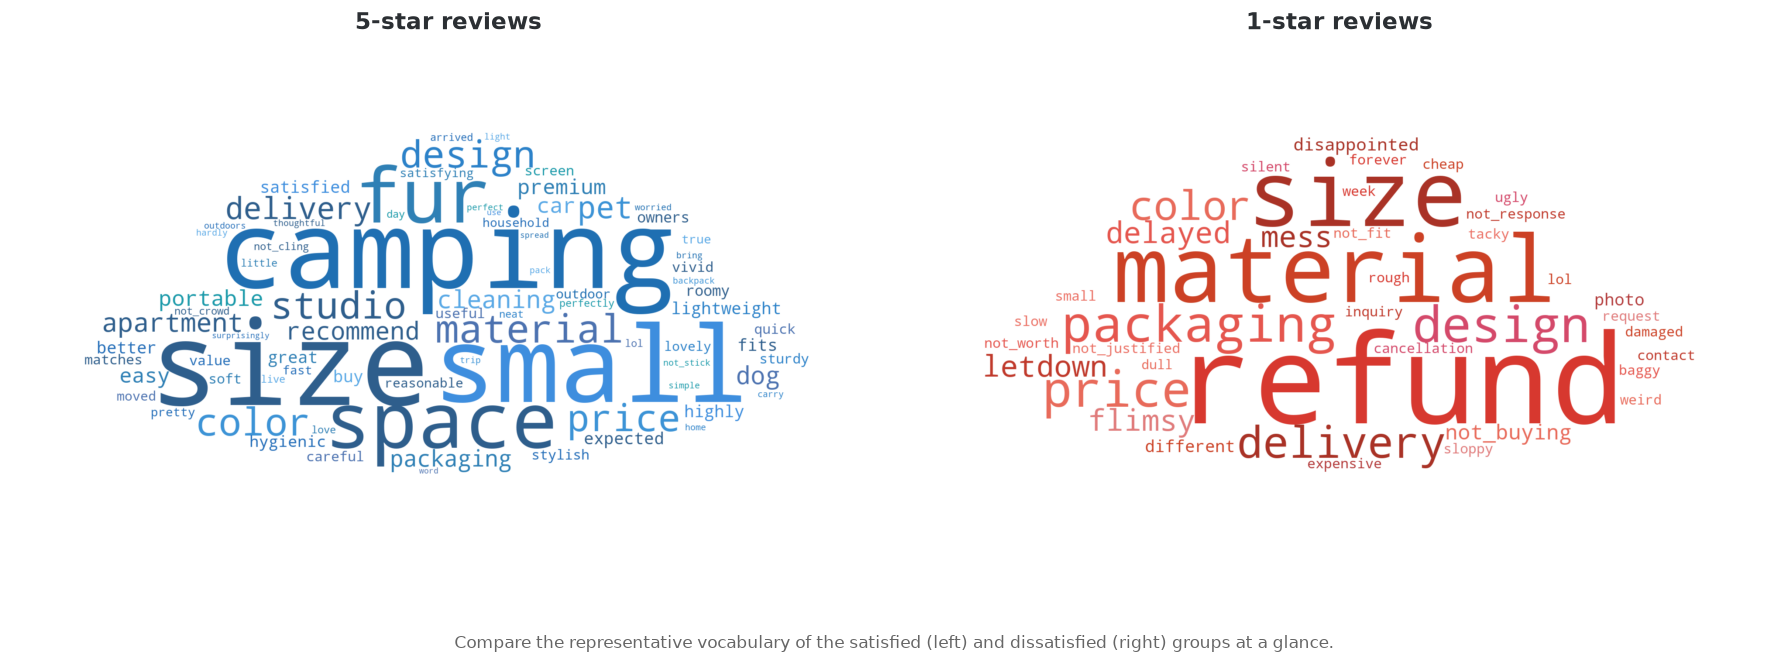

In [9]:
def draw_cloud(freq, palette):
    """Draw words horizontally (no rotation) inside the cloud-shaped mask."""
    return WordCloud(
        mask=MASK, scale=2,
        background_color="white", color_func=make_color_func(palette),
        prefer_horizontal=1.0,  # 1.0 = every word horizontal (no vertical rotation)
        relative_scaling=0.5, max_words=100,
        min_font_size=9, margin=2, random_state=42,
    ).generate_from_frequencies(freq)

def show_clouds(pos_freq, neg_freq, titles):
    """Draw the positive (left, blue) and negative (right, red) word clouds side by side."""
    fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=120)
    for ax, freq, title, palette in zip(
            axes, (pos_freq, neg_freq), titles, (BLUE_PALETTE, RED_PALETTE)):
        ax.imshow(draw_cloud(freq, palette), interpolation="bilinear")
        ax.set_title(title, fontsize=14, fontweight="bold",
                     color="#2b2f33", pad=12)
        ax.axis("off")
    fig.text(0.5, 0.02, "Compare the representative vocabulary of the satisfied (left) "
             "and dissatisfied (right) groups at a glance.",
             ha="center", fontsize=10, color="#666")
    plt.tight_layout(); plt.show()

show_clouds(pos_freq, neg_freq, ["5-star reviews", "1-star reviews"])

## 10.7.4. Text weighting analysis

Moving beyond raw frequency, we weight words by 'how important or distinctive is this word for a
particular group'. We go from the simplest unique keywords to TF-IDF and the log-odds ratio.

### 10.7.4.1. Unique keywords

We redraw the word clouds after removing the neutral words that both sides share. Subtracting the
intersection of the two top-keyword sets leaves only the words unique to each group, and the
difference becomes clear. Simple, but quite effective.

Notice the negation tokens — `not_buying`, `not_response` — surfacing on the 1-star side. That is
exactly what the negation rule in 10.7.2 was for: without it they would have been counted as
'buying' and 'response', and the complaint would have vanished.


5-star unique: ['camping', 'space', 'fur', 'studio', 'pet', 'apartment', 'cleaning', 'dog', 'recommend', 'car']
1-star unique: ['refund', 'flimsy', 'mess', 'delayed', 'letdown', 'not_buying', 'disappointed', 'different', 'photo', 'not_response']


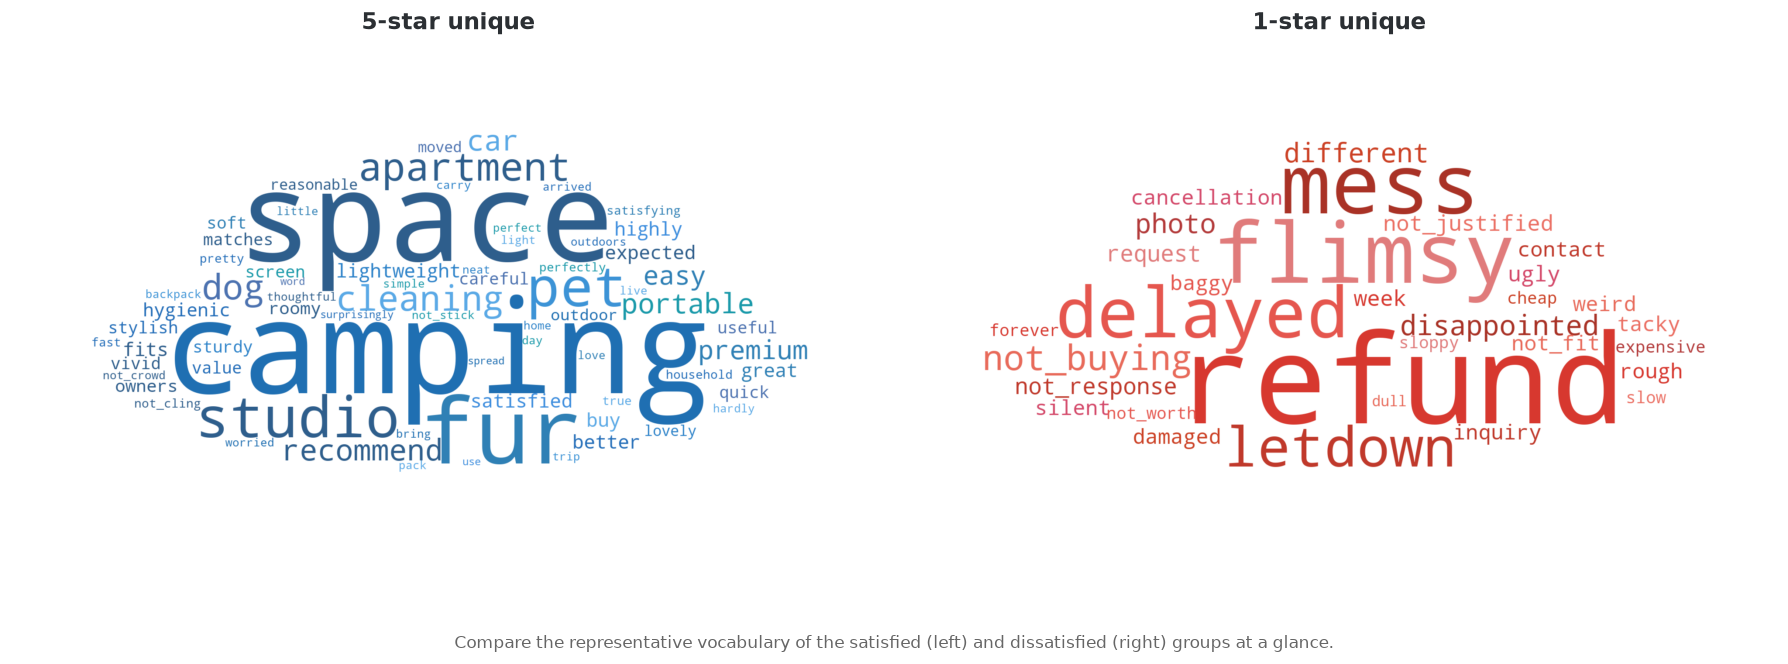

In [10]:
# [Apply to my data] Raise or lower the top-N cut (TOP) depending on how many reviews you have.
TOP = 100
pos_top = {w for w, _ in pos_freq.most_common(TOP)}
neg_top = {w for w, _ in neg_freq.most_common(TOP)}
common = pos_top & neg_top  # words shared (neutral) by both sides

pos_unique = {w: pos_freq[w] for w in pos_top - common}  # unique to 5-star
neg_unique = {w: neg_freq[w] for w in neg_top - common}  # unique to 1-star
print("5-star unique:", sorted(pos_unique, key=lambda w: (-pos_unique[w], w))[:10])
print("1-star unique:", sorted(neg_unique, key=lambda w: (-neg_unique[w], w))[:10])

show_clouds(pos_unique, neg_unique, ["5-star unique", "1-star unique"])

### 10.7.4.2. TF-IDF

We treat each review as one document, vectorize it, and look at the words with the highest mean
TF-IDF per group.

A word scores high when it appears often within one review (TF) but is rare across all reviews
(IDF). So a word that shows up everywhere, like 'delivery', sinks automatically, and words
specific to the group rise. Compared with plain frequency, context words such as 'camping',
'space', 'fur', 'studio', 'pet' climb to the top of the 5-star column, but words that appear on
both sides — 'size', 'material', 'color' — still linger in the top 15. That is because TF-IDF
measures 'which words matter within a review', not 'which words separate the two groups'
directly. That job belongs to the log-odds ratio, next.


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

# One review = one document (feed the tokens joined back together with spaces)
reviews["joined"] = reviews["text"].map(lambda t: " ".join(tokenize(t)))
# The input is already tokenized, so split on whitespace only — this keeps tokens like 'not_fit' intact
vec = TfidfVectorizer(token_pattern=r"(?u)[^\s]+")
X = vec.fit_transform(reviews["joined"])  # sparse matrix (reviews × words)
vocab = np.array(vec.get_feature_names_out())

# Mean TF-IDF per group — reuse the two groups (GROUP_A/B) defined in 10.7.1
pos_mean = np.asarray(X[GROUP_A.to_numpy()].mean(axis=0)).ravel()
neg_mean = np.asarray(X[GROUP_B.to_numpy()].mean(axis=0)).ravel()

def top_terms(mean_vec, n=15):
    """Top n words by mean TF-IDF as 'word · score' strings."""
    idx = mean_vec.argsort()[::-1][:n]
    return [f"{vocab[i]}  ·  {mean_vec[i]:.3f}" for i in idx]

tfidf_top = pd.DataFrame(
    {"5★ representative (word · TF-IDF)": top_terms(pos_mean),
     "1★ representative (word · TF-IDF)": top_terms(neg_mean)},
    index=pd.RangeIndex(1, 16, name="rank"),
)
tfidf_top.style.set_caption("Top keywords per group by TF-IDF") \
              .set_properties(**{"text-align": "left"})

,5★ representative (word · TF-IDF),1★ representative (word · TF-IDF)
rank,,
1,camping · 0.106,refund · 0.194
2,space · 0.101,flimsy · 0.099
3,fur · 0.095,letdown · 0.097
4,size · 0.095,not_buying · 0.096
5,small · 0.091,mess · 0.096
6,studio · 0.089,delayed · 0.093
7,apartment · 0.084,disappointed · 0.087
8,pet · 0.083,packaging · 0.087
9,recommend · 0.083,material · 0.086


### 10.7.4.3. Log-odds ratio

Where TF-IDF looks at 'words that stand out in this group', the log-odds ratio directly measures
'which of the two groups does this word lean toward, and how far'. We draw a diverging bar chart
that splits left and right around 0, so you can see at a glance which words represent the 5-star
(green) or 1-star (red) side, and how strongly. (We use the z-score with an informative Dirichlet
prior from Monroe et al. 2008.)


In [12]:
def log_odds_z(freq_a, freq_b, alpha0=1000):
    """Log-odds ratio with an informative Dirichlet prior (z-score), Monroe et al. (2008).
    z>0 leans 5-star, z<0 leans 1-star. The prior (alpha0) damps the overrating of rare words."""
    vocab = set(freq_a) | set(freq_b)
    bg = Counter(freq_a) + Counter(freq_b)              # background = both groups combined
    n_bg = sum(bg.values())
    na, nb = sum(freq_a.values()), sum(freq_b.values())
    out = {}
    for w in vocab:
        a_w = alpha0 * bg[w] / n_bg  # informative prior (proportional to background frequency)
        ya, yb = freq_a.get(w, 0), freq_b.get(w, 0)
        delta = (np.log(ya + a_w) - np.log(na + alpha0 - ya - a_w)
                 - np.log(yb + a_w) + np.log(nb + alpha0 - yb - a_w))
        var = 1.0 / (ya + a_w) + 1.0 / (yb + a_w)       # approximate variance
        out[w] = delta / np.sqrt(var)  # divide by the variance to get a z-score
    return out

scores = log_odds_z(pos_freq, neg_freq)

With these scores we draw the diverging bars that separate the two groups.

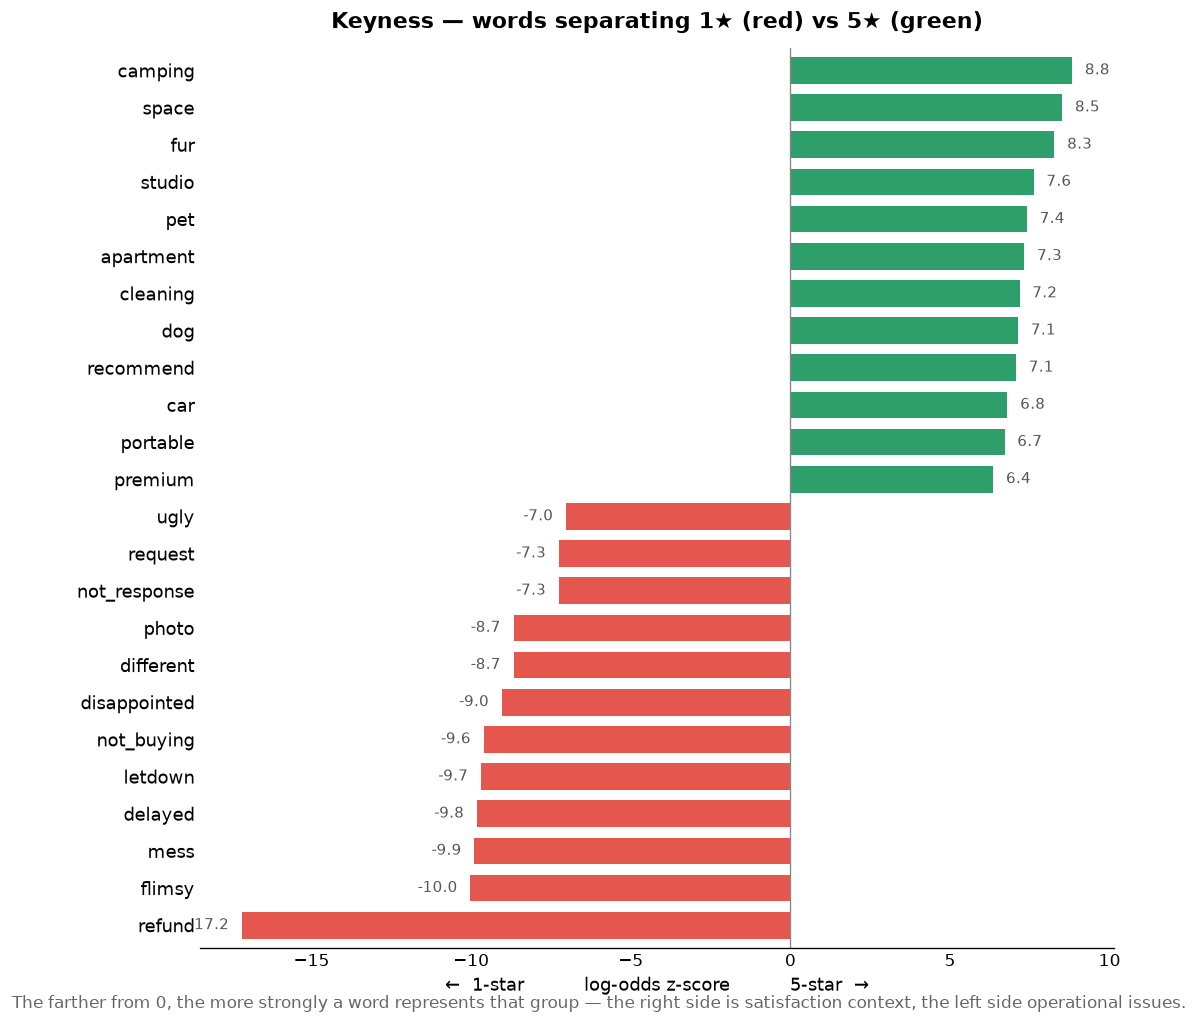

In [13]:
pos12 = sorted(scores, key=scores.get, reverse=True)[:12]  # top 12 on the 5-star side
neg12 = sorted(scores, key=scores.get)[:12]  # top 12 on the 1-star side
sel = neg12 + pos12[::-1]  # bottom = 1★, top = 5★
vals = [scores[w] for w in sel]
colors = [POS_GREEN if v >= 0 else NEG_RED for v in vals]

fig, ax = plt.subplots(figsize=(9, 8.5), dpi=120)
ax.barh(range(len(sel)), vals, color=colors, height=0.72)
ax.set_yticks(range(len(sel))); ax.set_yticklabels(sel, fontsize=11)
ax.set_ylim(-0.6, len(sel) - 0.4)
ax.axvline(0, color="#888", lw=0.8)
for i, v in zip(range(len(sel)), vals):  # write the z value at the end of each bar
    ax.text(v + (0.4 if v >= 0 else -0.4), i, f"{v:.1f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color="#555")
ax.set_title("Keyness — words separating 1★ (red) vs 5★ (green)",
             fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("←  1-star          log-odds z-score          5-star  →",
              fontsize=11)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.tick_params(length=0)
fig.text(0.5, 0.005, "The farther from 0, the more strongly a word represents that group — "
         "the right side is satisfaction context, the left side operational issues.",
         ha="center", fontsize=10, color="#666")
plt.tight_layout(); plt.show()

## 10.7.5. Word association and network analysis

Beyond the importance of individual words, we look at how words connect to form context.

### 10.7.5.1. Bigrams

A single word cannot tell you whether 'size' was good or too small. Counting pairs of consecutive
words (bigrams) reveals the surrounding context a single word hides, like 'size → small' or
'request → not_response'.


In [14]:
def bigrams_of(texts):
    """Extract every pair of 'two consecutive words (bigram)' from each review.
    zip(toks, toks[1:]) yields neighboring pairs: (1st,2nd), (2nd,3rd), ..."""
    rows = []
    for text in texts:
        toks = tokenize(text)
        for a, b in zip(toks, toks[1:]):   # two tokens that appeared right next to each other
            rows.append((a, b))
    return pd.DataFrame(rows, columns=["word1", "word2"])

# Top 15 word pairs that most often appeared together in 1-star reviews
neg_bigrams = bigrams_of(neg).value_counts().reset_index(name="n")
neg_bigrams.head(15)

,word1,word2,n
0,different,photo,94
1,refund,request,66
2,request,not_response,66
3,material,flimsy,66
4,packaging,mess,63
5,price,not_justified,62
6,size,small,62
7,design,ugly,62
8,delivery,delayed,62
9,delayed,week,62


Drawing these pairs as a directed graph (first word → second word) shows the flow of expression at
a glance. (Unlike the co-occurrence network, bigrams have an order, so we draw a directed graph
with arrows.)


In [15]:
import networkx as nx
import matplotlib.patheffects as pe

# Build a 'directed' graph from the top bigrams (pairs that often appear together).
TOPN = 25
top_bg = neg_bigrams.head(TOPN)

BG = nx.DiGraph()
for _, row in top_bg.iterrows():
    BG.add_edge(row["word1"], row["word2"], weight=row["n"])

# Node size = (weighted) degree → the more connected a word, the bigger it is drawn
deg = dict(BG.degree(weight="weight"))
dmax = max(deg.values())
node_size = [220 + 620 * (deg[n] / dmax) for n in BG.nodes]
wmax = top_bg["n"].max()

Next we compute a spring layout that spreads the nodes naturally, and define and apply a post-processing step (separate) that pushes nearby nodes apart so labels do not overlap.

In [16]:
# Spring layout: connected nodes attract, unconnected nodes repel, so the graph spreads out naturally
layout = nx.spring_layout(BG, k=2.8, iterations=450, seed=42)

def separate(pos, min_dist=0.36, iters=200):
    keys = list(pos)
    P = np.array([pos[k] for k in keys], dtype=float)
    for _ in range(iters):
        moved = False
        for i in range(len(keys)):
            for j in range(i + 1, len(keys)):
                d = P[i] - P[j]; dist = float(np.hypot(*d))
                if dist < min_dist:
                    if dist < 1e-9:
                        d = np.array([np.cos(i + j), np.sin(i + j)]); dist = 1.0
                    s = d / dist * (min_dist - dist) / 2
                    P[i] += s; P[j] -= s; moved = True
        if not moved:
            break
    return {k: P[i] for i, k in enumerate(keys)}

layout = separate(layout)

We draw the graph we built as an arrow network.

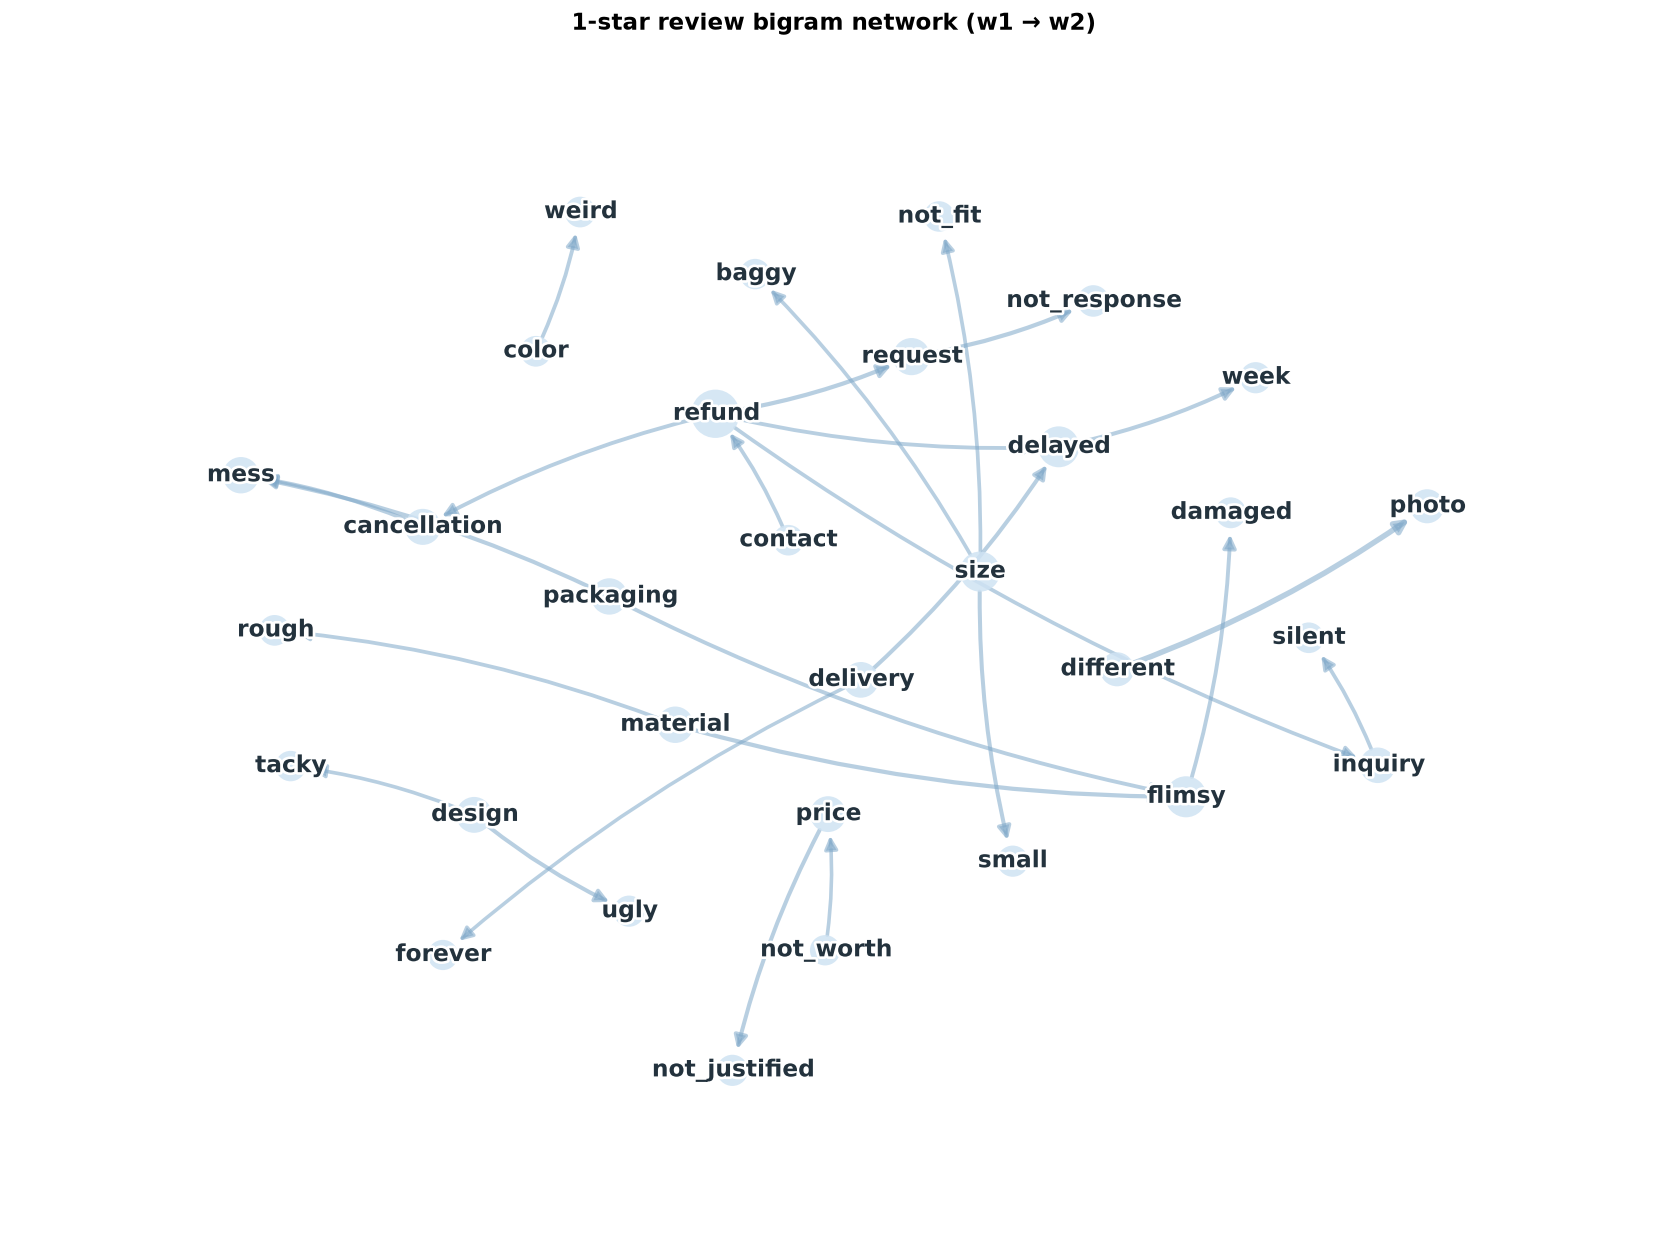

In [17]:
plt.figure(figsize=(14, 10.5), dpi=120)
nx.draw_networkx_nodes(BG, layout, node_color="#cfe3f3", node_size=node_size,
                       linewidths=0, alpha=0.85)
nx.draw_networkx_edges(
    BG, layout, node_size=node_size, edge_color="#7FA8C9",
    width=[0.7 + 2.6 * BG[u][v]["weight"] / wmax for u, v in BG.edges],
    alpha=0.55, arrows=True, arrowsize=16, arrowstyle="-|>",
    connectionstyle="arc3,rad=0.07", min_source_margin=8, min_target_margin=13,
)
# White halo around the labels for readability
for n, (x, y) in layout.items():
    plt.text(x, y, n, fontsize=14, fontweight="bold", ha="center", va="center",
             color="#23323d",
             path_effects=[pe.withStroke(linewidth=3.2, foreground="white")])
plt.title("1-star review bigram network (w1 → w2)",
          fontsize=14, fontweight="bold", pad=10)
plt.margins(0.13)
plt.axis("off"); plt.tight_layout(); plt.show()

### 10.7.5.2. Co-occurrence network

Where bigrams only look at 'right next to each other', co-occurrence looks at word pairs that
'appear in the same review'. Links are based not on raw co-occurrence counts but on **PMI** (how
much more often than chance two words appear together), which removes the noise of common words
linking to everything. Coloring the groups of words that cluster together (communities) shows at a
glance how the 1-star complaints split into **clusters** such as delivery, refund (customer
service), packaging, material, size, and design / color.


In [18]:
import math
from itertools import combinations
from networkx.algorithms.community import greedy_modularity_communities

PALETTE = ["#E5564E", "#2F80B5", "#2E9E6B", "#E8913A",
           "#7C5CBF", "#1AA3A3", "#D4496A", "#8C8C8C"]
NET_DROP = {"recommend", "satisfied", "disappointed", "letdown"}  # generic closers, dropped from the drawings only

def npmi_pairs(docs, word_df, min_word, min_pair):
    """From per-review word sets, return word pairs with positive NPMI, sorted by score."""
    pair_df = Counter()
    for d in docs:
        for a, b in combinations(sorted(d), 2):  # every word pair within one review
            pair_df[(a, b)] += 1
    N = len(docs)
    cand = []
    for (a, b), c in pair_df.items():
        if c < min_pair or word_df[a] < min_word or word_df[b] < min_word:
            continue  # skip pairs / words that are too rare
        p_xy, p_x, p_y = c / N, word_df[a] / N, word_df[b] / N
        # normalize away the frequency bias → keep only 'real' associations
        npmi = math.log(p_xy / (p_x * p_y)) / (-math.log(p_xy))
        if npmi > 0:
            cand.append((npmi, a, b))
    return sorted(cand, reverse=True)

Using this edge tally, we define a function that builds the co-occurrence network and groups the words into clusters with community detection.

In [19]:
def build_cooccurrence(texts, title, top_edges=40, min_word=22,
                       min_pair=12, exclude=None):
    """Aggregate co-occurring pairs into a network of the top NPMI edges and group them into communities.
    - exclude: words to leave out of the analysis (e.g. aspect words common to both sides).
    [Apply to my data] Tune min_word / min_pair to your corpus size — raise them with more
    reviews to filter noise, lower them with fewer reviews so nodes survive.
    top_edges is the number of links shown in the drawing."""
    exclude = (exclude or set()) | NET_DROP  # always drop the generic closer noise
    docs = [set(tokenize(t)) - exclude for t in texts]  # word set per review
    word_df = Counter(w for d in docs for w in d)  # number of reviews each word appears in
    G = nx.Graph()
    for pmi, a, b in npmi_pairs(docs, word_df, min_word, min_pair)[:top_edges]:
        G.add_edge(a, b, weight=pmi)

    # Community detection → words that are densely connected to each other form one cluster
    comms = list(greedy_modularity_communities(G, weight="weight"))
    print(f"[{title}] {G.number_of_nodes()} words · "
          f"{G.number_of_edges()} edges · {len(comms)} clusters")
    for i, com in enumerate(comms):
        words = " ".join(sorted(com, key=lambda w: -word_df[w]))
        print(f"  cluster {i+1}:", words)
    return G, word_df, comms

We define a function that lays the aggregated network out on a grid, one cell per community.

In [20]:
def community_layout(G, comms):
    """Place each cluster in its own grid cell — spring layout inside the cell, then reuse
    separate() from the 10.7.5.1 bigram section to clear up label overlap."""
    cols = math.ceil(math.sqrt(len(comms)))
    DX, DY = 2.9, 2.7
    centers = {i: np.array([(i % cols) * DX, -(i // cols) * DY])
               for i in range(len(comms))}
    layout = {}
    for i, com in enumerate(comms):
        spread = 0.5 + 0.07 * len(com)  # bigger clusters spread wider
        if len(com) > 1:
            sp = nx.spring_layout(G.subgraph(com), k=0.9,
                                  iterations=200, seed=42)
        else:
            sp = {next(iter(com)): np.array([0.0, 0.0])}
        for n, p in sp.items():
            layout[n] = centers[i] + np.asarray(p, float) * spread
    return separate(layout, min_dist=0.40, iters=220)

We define the function that actually draws nodes, edges and labels on these coordinates.

In [21]:
def draw_cooccurrence(G, word_df, comms, title):
    ncolor = {n: PALETTE[i % len(PALETTE)]
              for i, com in enumerate(comms) for n in com}
    fmax = max(word_df[n] for n in G.nodes)
    node_size = [220 + 1000 * word_df[n] / fmax for n in G.nodes]
    wmax = max(d["weight"] for *_, d in G.edges(data=True))
    e_width = [1.0 + 3.0 * G[u][v]["weight"] / wmax for u, v in G.edges]
    layout = community_layout(G, comms)

    fig, ax = plt.subplots(figsize=(12, 7.6), dpi=120)
    ax.set_axis_off()
    nx.draw_networkx_edges(G, layout, ax=ax, edge_color="#c4ccd3", alpha=0.7,
                           width=e_width)
    nx.draw_networkx_nodes(G, layout, ax=ax, node_size=node_size, linewidths=0,
                           node_color=[ncolor[n] for n in G.nodes], alpha=0.9)
    for n, (x, y) in layout.items():
        ax.text(x, y, n, fontsize=14, fontweight="bold", ha="center",
                va="center", color="#1f2a31",
                path_effects=[pe.withStroke(linewidth=3.2, foreground="white")])
    xs = [p[0] for p in layout.values()]; ys = [p[1] for p in layout.values()]
    ax.set_xlim(min(xs) - 0.8, max(xs) + 0.8)
    ax.set_ylim(min(ys) - 0.55, max(ys) + 0.55)
    ax.set_title(title, fontsize=13, fontweight="bold", pad=8)
    fig.subplots_adjust(left=0.01, right=0.99, top=0.94, bottom=0.02)
    plt.show()

We wrap the two functions in cooccurrence_network and draw the network of the 1-star reviews.

[1-star co-occurrence network — PMI, grouped by cluster] 36 words · 40 edges · 8 clusters
  cluster 1: design color different photo ugly weird tacky dull
  cluster 2: packaging flimsy mess cancellation damaged sloppy
  cluster 3: delivery delayed week forever slow
  cluster 4: refund inquiry contact silent
  cluster 5: price not_justified not_worth expensive
  cluster 6: size small not_fit baggy
  cluster 7: material rough cheap
  cluster 8: request not_response


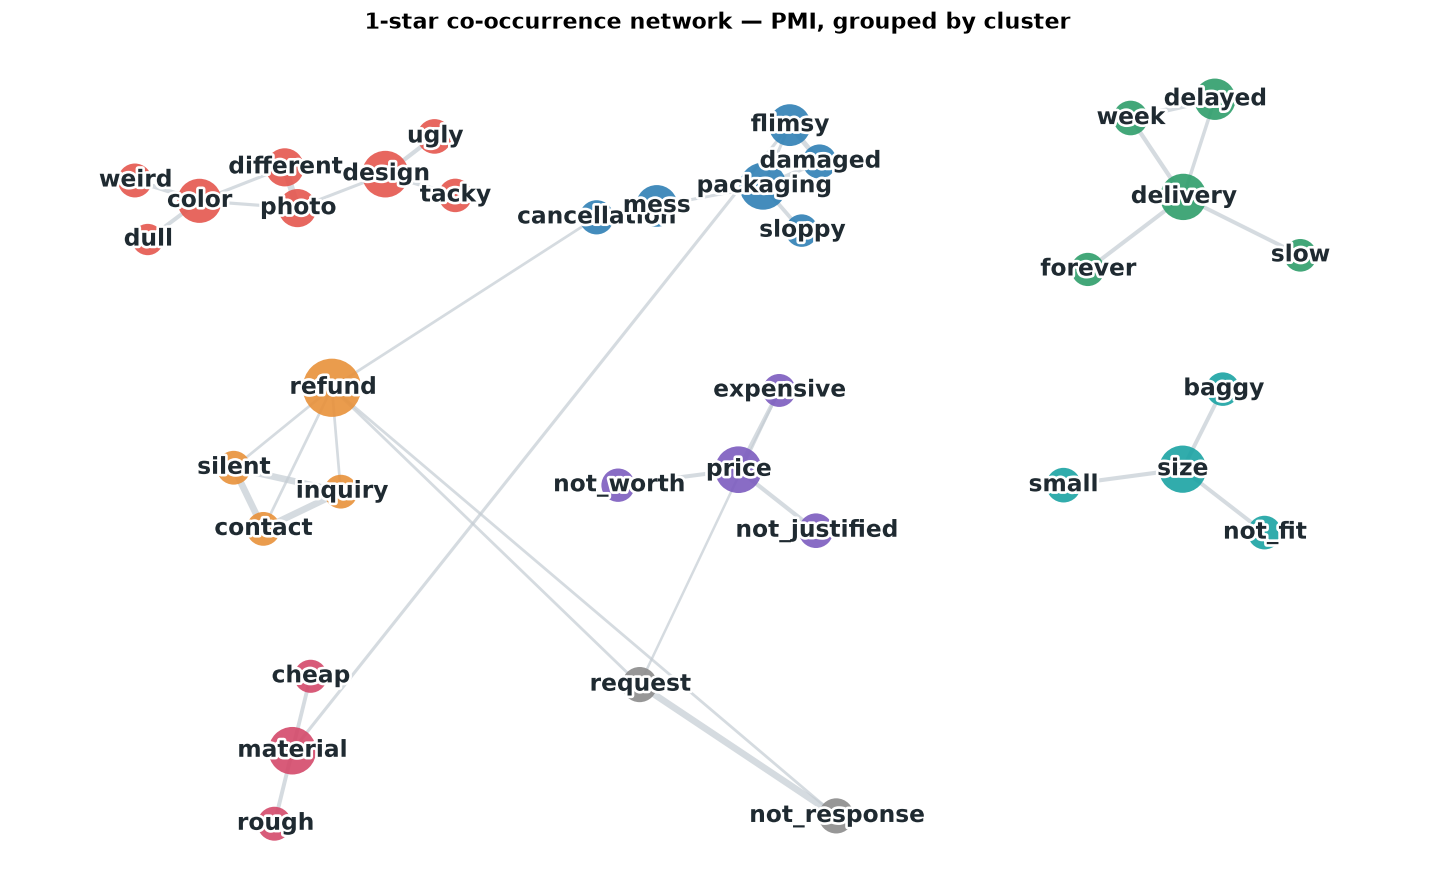

In [22]:
def cooccurrence_network(texts, title, **kwargs):
    """Aggregate (build) and draw in one go.
    The 5-star network in 10.7.8 uses this same function."""
    G, word_df, comms = build_cooccurrence(texts, title, **kwargs)
    draw_cooccurrence(G, word_df, comms, title)
    return G

_ = cooccurrence_network(
    neg, "1-star co-occurrence network — PMI, grouped by cluster")

## 10.7.6. Topic modeling (LDA)

Topic modeling automatically groups the latent themes in tens of thousands of reviews. We read
each topic off its top words and compute, as a number, how much each review belongs to each
topic. (Naming the topics, though, is something a person has to do.) That 'topic share per
document' is exactly what turns a qualitative theme into a countable number — something the
network could not do.


In [23]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# LDA takes raw word counts as input, not TF-IDF.
# max_df=0.5 : drop words that appear in more than half of the documents (too common)
# min_df=10  : drop rare words that appear in fewer than 10 documents
cv = CountVectorizer(max_df=0.5, min_df=10, token_pattern=r"(?u)[^\s]+")
dtm = cv.fit_transform(reviews["joined"])  # reuse the tokenized documents built above
# [Apply to my data] There is no right number of topics (n_components). Try 5-15 and pick
#   the one that is easiest to interpret; with few reviews, lower max_df / min_df as well.
lda = LatentDirichletAllocation(n_components=5, random_state=2)
doc_topic = lda.fit_transform(dtm)  # topic share of each review (reviews × 5)

# Print the top 8 words of each topic
terms = np.array(cv.get_feature_names_out())
for k, comp in enumerate(lda.components_):
    print(f"Topic {k}:", " ".join(terms[comp.argsort()[::-1][:8]]))

Topic 0: small space studio apartment size fits material color
Topic 1: camping portable car size lightweight design easy cleaning
Topic 2: recommend dog fur pet owners delivery highly material
Topic 3: refund design material size packaging delivery price color
Topic 4: okay delivery packaging color light backpack carry price


We draw each topic's top words as bars so you can see the evidence behind the topic labels.

In the example data four of the five topics name themselves straight from their top words —
'studio / space' (the intended use), 'camping / portable' (the discovered use case), 'dog / fur /
pet' (the discovered segment), and 'refund + aspect complaints' (the 1-star reviews). The fifth
topic, led by 'okay', is a mixed bag: the 2-4 star 'just okay' reviews plus a stray camping phrase
('light enough to carry in a backpack'). That is normal — a topic you cannot name is the signal to
try a different `n_components`. (Topic numbers can change between runs; read the words, not the
numbers.)


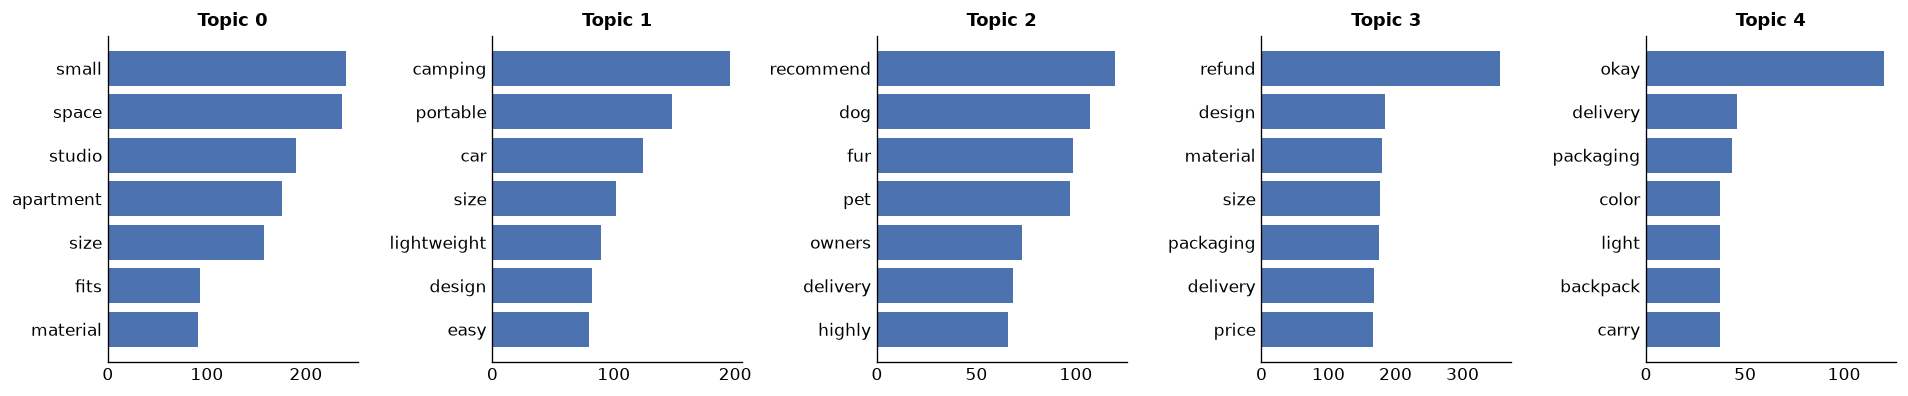

In [24]:
n = lda.n_components
fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.4), dpi=120)
for k, ax in enumerate(axes):
    comp = lda.components_[k]
    idx  = comp.argsort()[::-1][:7]
    ax.barh(range(len(idx)), comp[idx][::-1], color="#4C72B0")
    ax.set_yticks(range(len(idx)))
    ax.set_yticklabels(terms[idx][::-1], fontsize=10)
    ax.set_title(f"Topic {k}", fontsize=11, fontweight="bold")
    ax.tick_params(length=0)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

We can also check how much each review belongs to each topic (`doc_topic`). Because the topic
order can change when you change the number of topics or the seed, the code below builds a
temporary label from each topic's top 2 words and uses it as the column name, and picks the
topics to inspect by an anchor word ('camping', 'refund') rather than by a hard-coded topic
number. A review focused on one theme has a single topic share above 90%, while a review that
mixes several stories splits its share between two topics.


In [25]:
# Label the topic shares (doc_topic) with a temporary label made from the top 2 words.
# (Read the top words above and write the final labels by hand)
TOPIC_LABELS = ["·".join(terms[c.argsort()[::-1][:2]]) for c in lda.components_]
dt = pd.DataFrame(doc_topic, columns=TOPIC_LABELS)

def topic_share(i):
    """Topic shares of review i as 'label NN%' strings, highest first."""
    s = dt.iloc[i].sort_values(ascending=False)
    return " · ".join(f"{lab} {p*100:.0f}%"
                      for lab, p in s.items() if p >= 0.1)

def topic_with(word):
    """Index of the topic that gives `word` the most weight — so we do not hard-code topic numbers,
    which change whenever the data, n_components or the seed changes."""
    return int(lda.components_[:, list(terms).index(word)].argmax())

# Pick 2 reviews focused on one theme + 1 review that mixes several themes, and compare
# [Apply to my data] Replace the anchor words with ones from your own top-word printout above.
i_focus1 = doc_topic[:, topic_with("camping")].argmax()  # highest share of the 'camping' topic
i_focus2 = doc_topic[:, topic_with("refund")].argmax()   # highest share of the 'refund' topic
i_mixed = np.sort(doc_topic, axis=1)[:, -2].argmax()  # review whose 2nd-largest share is largest

pd.DataFrame({
    "review": [reviews["text"].iloc[i][:40] + "…"
               for i in (i_focus1, i_focus2, i_mixed)],
    "topic share": [topic_share(i) for i in (i_focus1, i_focus2, i_mixed)],
})

,review,topic share
0,Portable enough for outdoor use like cam…,camping·portable 97%
1,"Design is different from the photo, cont…",refund·design 95%
2,"Delivery arrived in a day, would buy aga…",recommend·dog 49% · small·space 48%


### Topic time series — themes rise and fade over time

With the code below you can look at the mean topic share per week, i.e. when a theme rises and
when it fades. Just pair each review's topic shares (`doc_topic`) with its date and average them
by week. In the chart below, the intended use — **studio / small space** — is concentrated early
on, while the later-discovered **camping / portable** and **dog / pet** uses widen their share
as time goes on. The 'spread of a discovery' that 10.7.8 talks about shows up on the time axis
as well.


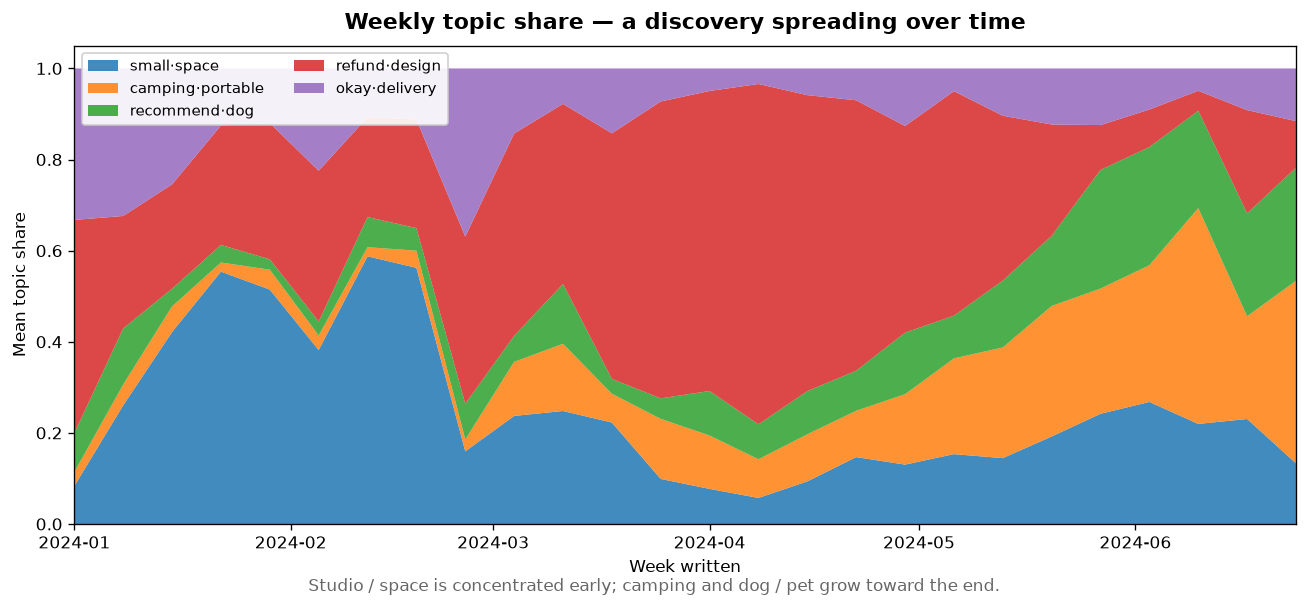

In [26]:
# [Apply to my data] Works only when you have a date column such as created_at.
reviews["created_at"] = pd.to_datetime(reviews["created_at"])
week = reviews["created_at"].dt.to_period("W").dt.start_time
weekly = dt.assign(week=week.values).groupby("week")[TOPIC_LABELS].mean()

fig, ax = plt.subplots(figsize=(11, 5), dpi=120)
ax.stackplot(weekly.index, *[weekly[c] for c in TOPIC_LABELS],
             labels=TOPIC_LABELS, alpha=0.85)
ax.legend(loc="upper left", fontsize=9, ncol=2, framealpha=0.9)
ax.set_title("Weekly topic share — a discovery spreading over time",
             fontsize=13, fontweight="bold", pad=10)
ax.set_xlabel("Week written"); ax.set_ylabel("Mean topic share")
ax.margins(x=0)
fig.text(0.5, 0.005, "Studio / space is concentrated early; "
         "camping and dog / pet grow toward the end.",
         ha="center", fontsize=10, color="#666")
plt.tight_layout(); plt.show()

### [notebook extra] Sentiment analysis · embeddings · LLMs

Other ways to analyze the context of qualitative data include **sentiment analysis** (especially
aspect-based, ABSA), **embeddings** (grouping phrases that look different but mean nearly the
same), and **LLM-based analysis** (reading, classifying and summarizing the way a person would)
(10.4.2). Each is a vast subject that fills books of its own, so this notebook skips the code
practice. Embedding clustering (`sentence-transformers`) and LLM calls also need heavy
dependencies or API keys. If you are interested, use the keywords in the book as a starting point
for further study. (The 'representative reviews' in 10.7.7 below achieve the same effect with LDA
topic shares instead of embedding clusters.)


## 10.7.7. Checking the concrete context in the original text

Reading the left and right context around a keyword (KWIC) and the representative reviews with
the highest LDA topic share lets you check the concrete context in the original text. This is the
step where we do not stop at abstract numbers but come down to actual sentences, confirm the
signal is real, and restore the nuance the numbers blurred. (KWIC matches the keyword literally,
so it catches 'refund' but a similar word like 'return' has to be searched separately.)


In [27]:
def kwic(texts, keyword, width=20, n=8):
    """Show reviews that contain keyword as a table, with left and right context (case-insensitive)."""
    rows = []
    for t in texts:
        s = str(t)
        i = s.lower().find(keyword.lower())
        if i >= 0:
            rows.append({"left context": "…" + s[max(0, i - width):i],
                         "keyword": s[i:i + len(keyword)],
                         "right context": s[i + len(keyword): i + len(keyword) + width] + "…"})
        if len(rows) >= n:
            break
    return pd.DataFrame(rows)

# [Apply to my data] Replace "refund" with the keyword you are curious about in your own analysis.
kwic(neg, "refund")


,left context,keyword,right context
0,"…ive for what it is,",refund,request got no resp…
1,"…y, contact about my",refund,inquiry went silent…
2,…,Refund,cancellation was a …
3,…Contact about my,refund,inquiry went silent…
4,"…Delivery was slow,",refund,"is still delayed, p…"
5,"…Color is dull,",refund,"is still delayed, p…"
6,"…Size is baggy,",refund,request got no resp…
7,"… damaged, give me a",refund,. :(…


Next we pull the representative review with the highest share for each LDA topic into a table.

In [28]:
rep_rows = []
for k in range(lda.n_components):
    i = doc_topic[:, k].argmax()  # the review with the highest share of topic k
    rep_rows.append({"topic": f"Topic {k}",
                     "share": f"{doc_topic[i, k] * 100:.0f}%",
                     "representative review": reviews["text"].iloc[i]})

rep = pd.DataFrame(rep_rows)
rep.style.hide(axis="index") \
    .set_caption("[Representative review per LDA topic] the review with the highest topic share") \
    .set_properties(**{"text-align": "left"})

topic,share,representative review
Topic 0,96%,"Perfect size for a small studio apartment space, packaging was neat, as a pet household the fur cleaning is easy and hygienic, better than expected, color is lovely, size fits perfectly."
Topic 1,97%,"Portable enough for outdoor use like camping and car camping, surprisingly useful, size is roomy, dog fur cleaning is so easy that word spread among pet owners, design looks premium, better than expected, color is vivid. :("
Topic 2,96%,"Highly recommend, bought it for home but it is so lightweight I bring it car camping, price is reasonable, dog fur does not cling so I recommend it to pet owners, material is sturdy, size is roomy. lol"
Topic 3,95%,"Design is different from the photo, contact about my refund inquiry went silent, color is dull, packaging was flimsy so the item got damaged, never buying again. lol"
Topic 4,93%,"Packaging was neat, light enough to carry in a backpack when camping, material is sturdy, size is roomy, overall very satisfied.!!"


## 10.7.8. What positive reviews reveal

Finally, we apply the co-occurrence network we have been using on 1-star reviews to the 5-star
reviews, unchanged. Complaints collapse flatly into a few operational issues such as delivery and
refunds. Satisfaction, on the other hand, comes out of each customer's own life context, so it is
far more multi-dimensional. In the 5-star network, clusters of 'use cases' and 'customer segments'
emerge. A product designed for a studio apartment turns out to be used for camping and car
camping, and by pet owners — clues to a competitive edge nobody thought of when the product was
planned. Remember: complaints are flat, satisfaction is multi-dimensional. Stripping out the
`flat_words` (stock phrases) carefully makes the result much clearer.


[5-star co-occurrence network — use cases & segments] 22 words · 48 edges · 3 clusters
  cluster 1: space small studio apartment not_crowd little perfect hardly
  cluster 2: fur pet cleaning dog hygienic not_cling not_stick
  cluster 3: camping car portable lightweight outdoor outdoors light


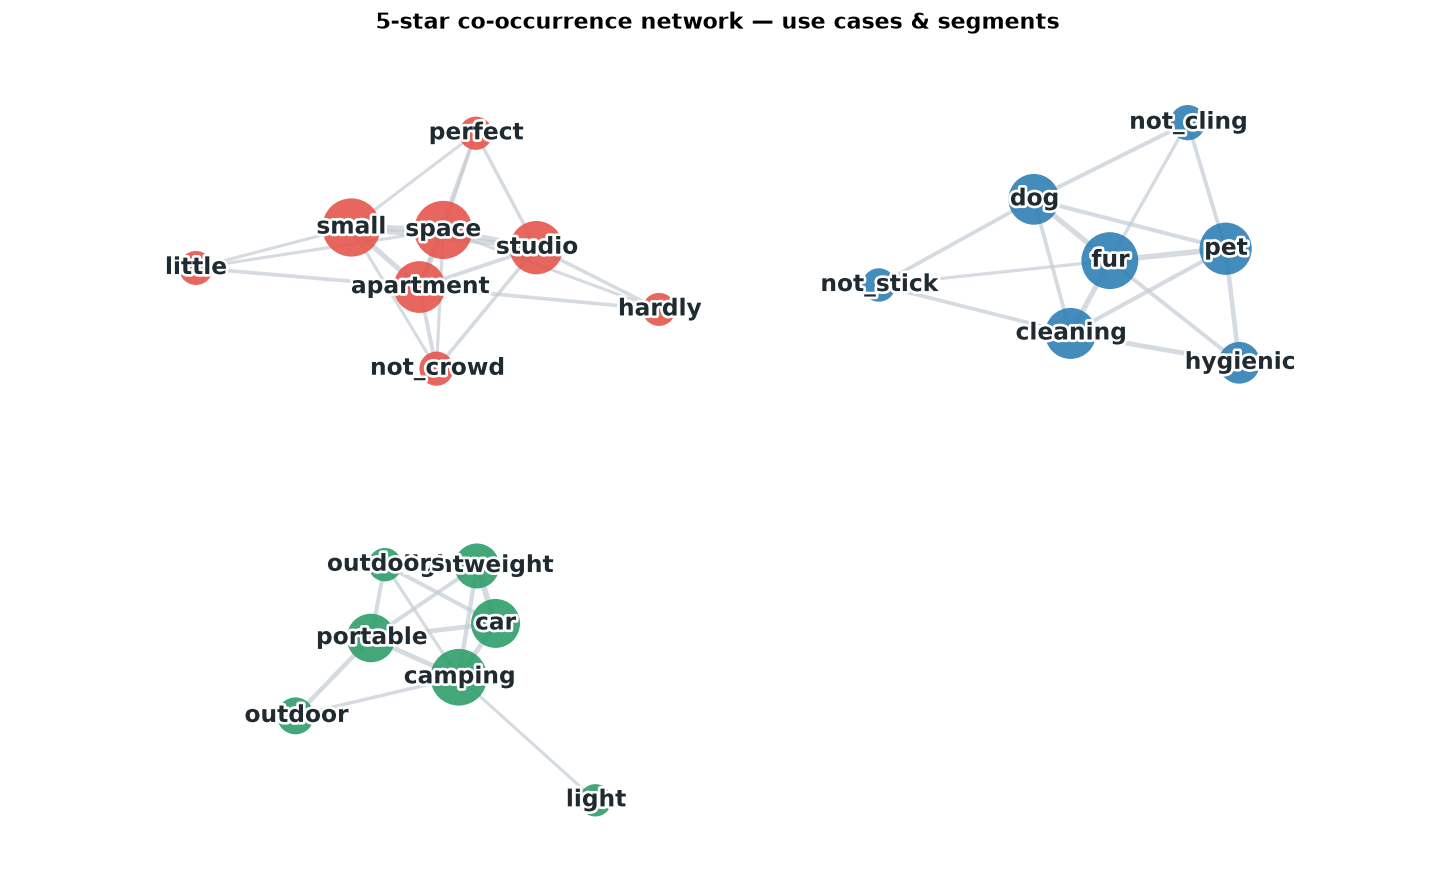

In [29]:
# Leave only 'context' words — drop aspect words, generic praise and generic verb noise
# [Apply to my data] Put the aspect words / stock phrases common to both groups in flat_words,
#   and swap them for your own category (cosmetics: scent, pigmentation, longevity; apparel: fit, fabric, shade).
flat_words = {
    # aspects (neutral nouns)
    "delivery", "price", "design", "color", "size", "material", "packaging",
    # positive opinion words per aspect
    "fast", "quick", "arrived", "day", "reasonable", "satisfying", "great",
    "value", "pretty", "stylish", "premium", "matches", "screen", "vivid",
    "lovely", "fits", "perfectly", "true", "roomy", "sturdy", "soft",
    "careful", "neat", "thoughtful",
    # closing stock phrases
    "satisfied", "buy", "highly", "recommend", "better", "expected",
    # generic verbs and filler that do not mark a context
    "home", "love", "worried", "moved", "live", "bring", "pack", "trip",
    "carry", "backpack", "use", "useful", "surprisingly", "household",
    "owners", "word", "spread", "simple", "easy", "stick", "cling",
}
_ = cooccurrence_network(pos,
                         "5-star co-occurrence network — use cases & segments",
                         top_edges=48, min_word=20, exclude=flat_words)

## Closing

Good qualitative analysis moves back and forth between abstraction and concreteness. You abstract
tens of thousands of sentences into frequencies, weights, networks and topics to get the big
picture, then come back down to the actual sentences the picture points at and check. This
notebook followed that path in the order frequency → weighting → association and networks →
topics and meaning → back to the original text → the discovery in positive reviews.

> **What we did not cover** — the sentiment analysis, embeddings and LLM-based analysis of 10.4.2
> need heavy dependencies or API keys, so this notebook settled for introducing the concepts.
> For going back to the original text (10.7.7), we picked representative reviews by LDA topic
> share instead of embedding clusters.
